# CCL example of the covariance of $C_\ell$ and clusters

In this example, we will illustrate how CCL produces the cross-covariances of $C_\ell$ and clusters

In [1]:
import numpy as np
import pylab as plt
import pyccl as ccl

## Define a cosmology
First step will be to define a cosmology object

In [2]:
cosmo = ccl.Cosmology(Omega_c = 0.27, Omega_b = 0.045, h = 0.67, sigma8 = 0.83, n_s = 0.96)

## Define a sample of galaxies

We do this via a redshift distribution for the galaxies. We will also define their bias parameter, which we assume to be constant in this example.

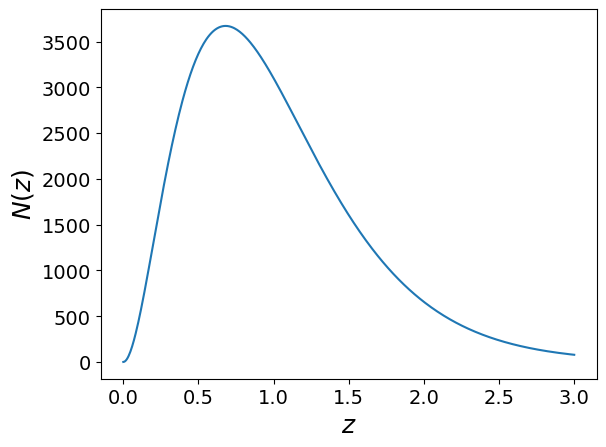

In [3]:
z = np.linspace(0., 3., 512)
i_lim = 26. # Limiting i-band magnitude
z0 = 0.0417*i_lim - 0.744

Ngal = 46. * 100.31 * (i_lim - 25.) # Normalisation, galaxies/arcmin^2
pz = 1./(2.*z0) * (z / z0)**2. * np.exp(-z/z0) # Redshift distribution, p(z)
dNdz = Ngal * pz # Number density distribution
b = 1.5*np.ones(512) #Galaxy bias (constant with scale and z)

plt.xlabel('$z$',fontsize=18)
plt.ylabel('$N(z)$',fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.plot(z, dNdz)
plt.show()

## Create Tracer objects

In [4]:
lens1 = ccl.WeakLensingTracer(cosmo, dndz=(z, dNdz)) #CCL automatically normalizes dNdz
clu1 = ccl.NumberCountsTracer(cosmo, has_rsd=False, dndz=(z,dNdz), bias=(z,b))

bias_ia = 1*np.ones_like(z) #A_IA=1 in the NLA model
lens1_ia = ccl.WeakLensingTracer(cosmo, dndz = (z,dNdz), ia_bias = (z,bias_ia))

Next, we create the bispectrum needed from the halomodel

In [5]:
k_arr = np.geomspace(1E-4,1E1,256)
a_arr = np.linspace(0.4,1,10)
hmd_200m = ccl.halos.MassDef200m
cM = ccl.halos.ConcentrationDuffy08(mass_def=hmd_200m)
nM = ccl.halos.MassFuncTinker08(mass_def=hmd_200m)
bM = ccl.halos.HaloBiasTinker10(mass_def=hmd_200m)

selection = lambda M, a: (M > 1e14).astype(float)

hmc = ccl.halos.HMCalculator(
        mass_function=nM,
        halo_bias=bM,
        mass_def=hmd_200m)

selection_wrapped = ccl.halos.HaloProfileSelection(mass_def=hmd_200m,
    selection=selection)  
pg = ccl.halos.HaloProfileHOD(mass_def=hmd_200m, concentration=cM)


Bk2D_SSC = ccl.halos.halomod_Pk2D_bispectrum_squeezed_SSC(cosmo,hmc, selection_wrapped, prof2=pg, a_arr=a_arr)
Bk2D = ccl.halos.halomod_Pk2D_bispectrum_squeezed(cosmo,hmc, selection_wrapped, prof2=pg, a_arr=a_arr)




## Calculating of the cross-variance between the angular power spectra and cluster counts

In [6]:
ell = np.arange(2, 2000)

cl_cross_cluster_SSC =ccl.angular_cl_cov_counts_SSC(cosmo, lens1_ia, lens1_ia, ell=ell, b_of_k_a =Bk2D_SSC, fsky = 0.2)
cl_cross_cluster_sva = ccl.angular_cl_cov_counts(cosmo, lens1_ia, lens1_ia, ell=ell, b_of_k_a =Bk2D)

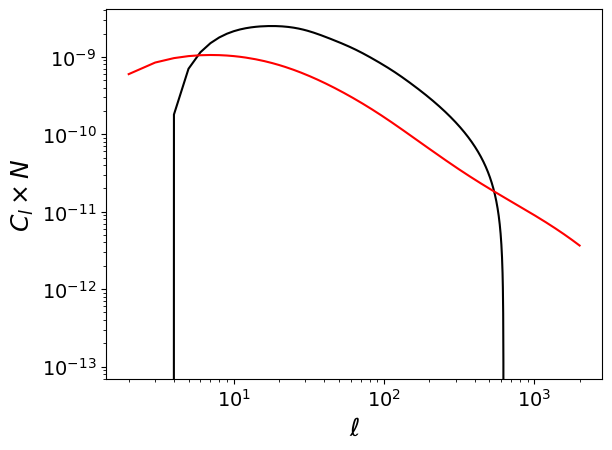

In [7]:


plt.xlabel('$\\ell$',fontsize=18)
plt.ylabel('$C_l\\times N$',fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.yscale('log')
plt.xscale('log')
plt.plot(ell, cl_cross_cluster_SSC, 'k-')
plt.plot(ell, cl_cross_cluster_sva, 'r-')
plt.show()